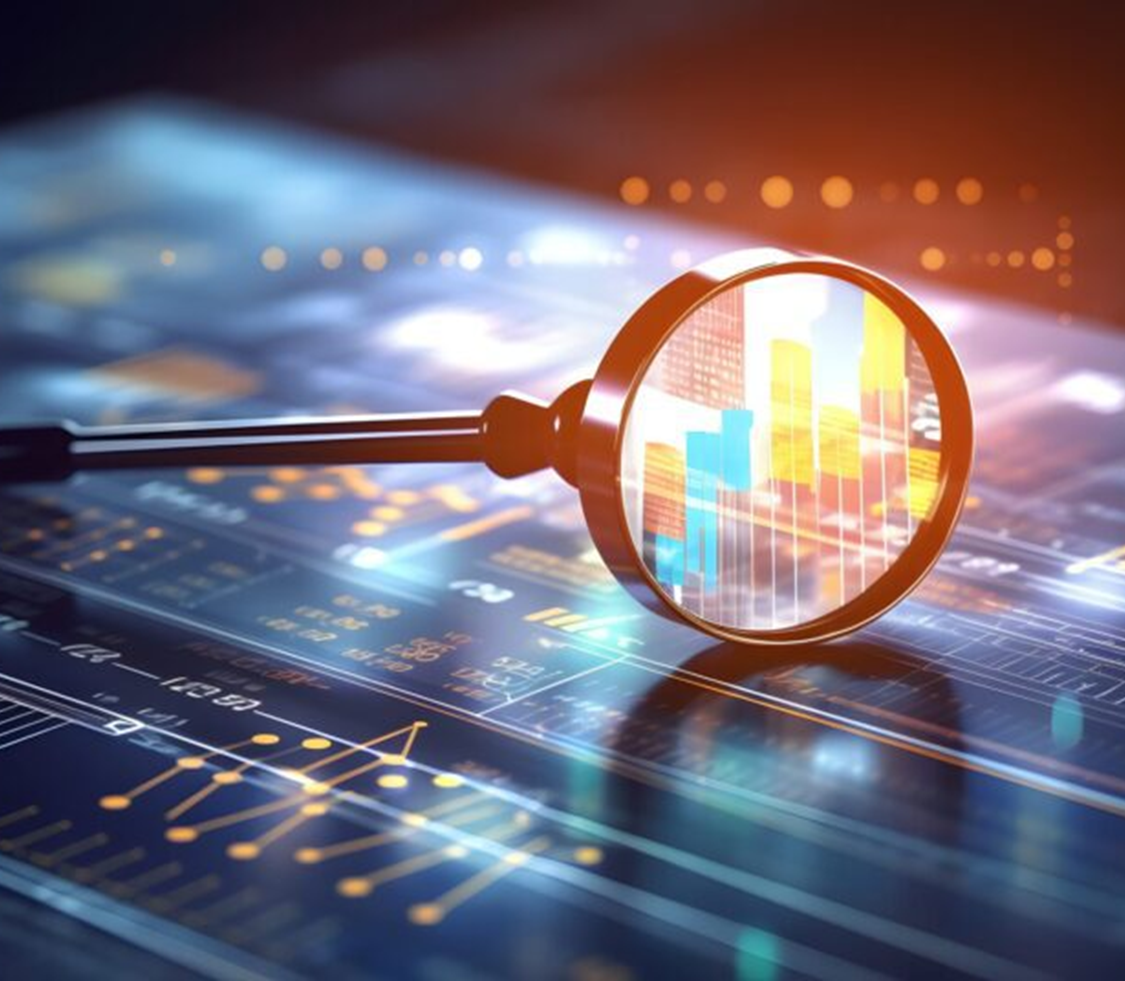</br>
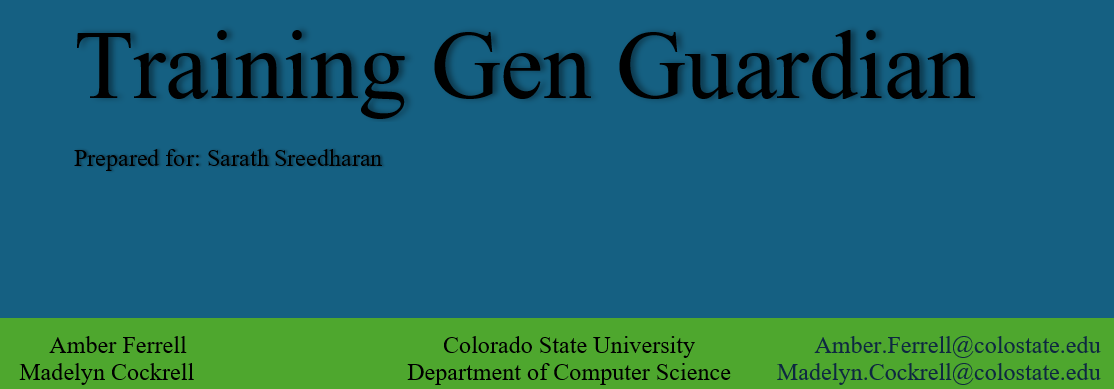

<h1 style="font-family: 'Times New Roman', Times, serif;">
    Introduction
</h1>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; ">
    The Gen Guardian project comes from the vision of creating a comprehensive parenting support app designed to foster emotional regulation and child development grounded in the Finnish education model and Montessori principles. The inspiration for the app lies in a parent-first model of regulation, which posits that a caregiver’s internal emotional state is the primary catalyst for a healthy home environment. A parent cannot effectively co-regulate a child while they themselves are in a state of emotional flooding or crisis especially if they did not grow up with a good parent to model from. While the full Gen Guardian application will eventually integrate Finnish pedagogical concepts and the emphasis on the child’s holistic well-being, the work presented here represents the essential technical foundation for such a system. By implementing a high-precision classification engine to identify parental emotional states this project establishes the logic required for future development. Utilizing a refined version of the dair-ai/emotion dataset, the following analysis compares a Keyword Heuristic Baseline ~44.08% accuracy against advanced models, including a Linear SVM ~92.17% accuracy and a Tuned Random Forest, to prove the feasibility of using machine learning as a reliable first step in the Gen Guardian development roadmap.
</div>


<div style="font-family: 'Times New Roman', Times, serif; font-size: 24px;">
 Setup and Imports
</div>

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.pipeline import Pipeline

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

<div style="font-family: 'Times New Roman', Times, serif; font-size: 24px;">
 Import dataset and extract emotion labels
 </div>

In [24]:
from datasets import load_dataset

dataset = load_dataset("dair-ai/emotion")
df = dataset['train'].to_pandas()


print("Label values:", df['label'].unique())
print("\nLabel distribution:")
print(df['label'].value_counts().sort_index())

print("\nDataset info:")
print(dataset['train'].features)


Label values: [0 3 2 5 4 1]

Label distribution:
label
0    4666
1    5362
2    1304
3    2159
4    1937
5     572
Name: count, dtype: int64

Dataset info:
{'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}


<div style="font-family: 'Times New Roman', Times, serif; font-size: 24px;">
Show Mapping
</div>

In [25]:
# emotion mapping 
emotion_map = {
    0: 'sadness',
    1: 'joy',
    2: 'love',
    3: 'anger',
    4: 'fear',
    5: 'surprise'
}

df['emotion_name'] = df['label'].map(emotion_map)

print("emotion mapping applied")
print("\nOriginal emotion distribution:")
print(df['emotion_name'].value_counts())

emotion mapping applied

Original emotion distribution:
emotion_name
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


<div style="font-family: 'Times New Roman', Times, serif; font-size: 24px;">
Consolidation for Gen Guardian
 </div>

In [26]:

consolidation_map = {
    'anger': 'anger/frustration',
    'fear': 'exhaustion/overwhelm',  # Fear → overwhelm
    'joy': 'calm/in-control',
    'love': 'calm/in-control',
    'sadness': 'sadness/disappointment',
    'surprise': 'confusion/uncertainty'  # Surprise → uncertainty
}

df['consolidated_emotion'] = df['emotion_name'].map(consolidation_map)



In [27]:
# Religious content filter
religious_patterns = [
    r'\bgod\b', r'\bjesus\b', r'\bchrist\b', r'\blord\b', 
    r'\bsavior\b', r'\bbible\b', r'\bchurch\b', r'\bprayer\b', 
    r'\bpray\b', r'\bfaith\b', r'\bholy\b', r'\bspirit\b', 
    r'\bgospel\b', r'\bscripture\b', r'\bcommandments\b', 
    r'\bpastor\b', r'\bpriest\b', r'\bbishop\b', r'\breligion\b', 
    r'\breligious\b', r'\bchristian\b', r'\bcatholic\b', 
    r'\bprotestant\b', r'\bworship\b', r'\bsalvation\b',
    r'\bsin\b', r'\bsinner\b', r'\bheaven\b', r'\bhell\b', 
    r'\bangel\b', r'\bsoul\b', r'\bdivine\b', r'\bblessed\b', 
    r'\bblessing\b', r'\bamen\b', r'\bhallelujah\b', r'\brighteous\b',
    r'\bprophet\b', r'\bdisciple\b', r'\bapostle\b', r'\btestament\b', 
    r'\bclergy\b', r'\bpreacher\b', r'\bsermon\b', r'\bministry\b', 
    r'\bbaptism\b', r'\bcommunion\b', r'\bcrucifixion\b', 
    r'\bresurrection\b', r'\bredeemer\b', r'\bmessiah\b',
    r'\breligious\b', r'\boffend\b', r'\boffended\b', r'\bidolatry\b'
]

pattern = '|'.join(religious_patterns)
mask = df['text'].str.lower().str.contains(pattern, regex=True, na=False)
df = df[~mask].copy()

print(f"Removed {mask.sum()} samples with religious language")
print(f"Remaining: {len(df)} samples")

Removed 617 samples with religious language
Remaining: 15383 samples


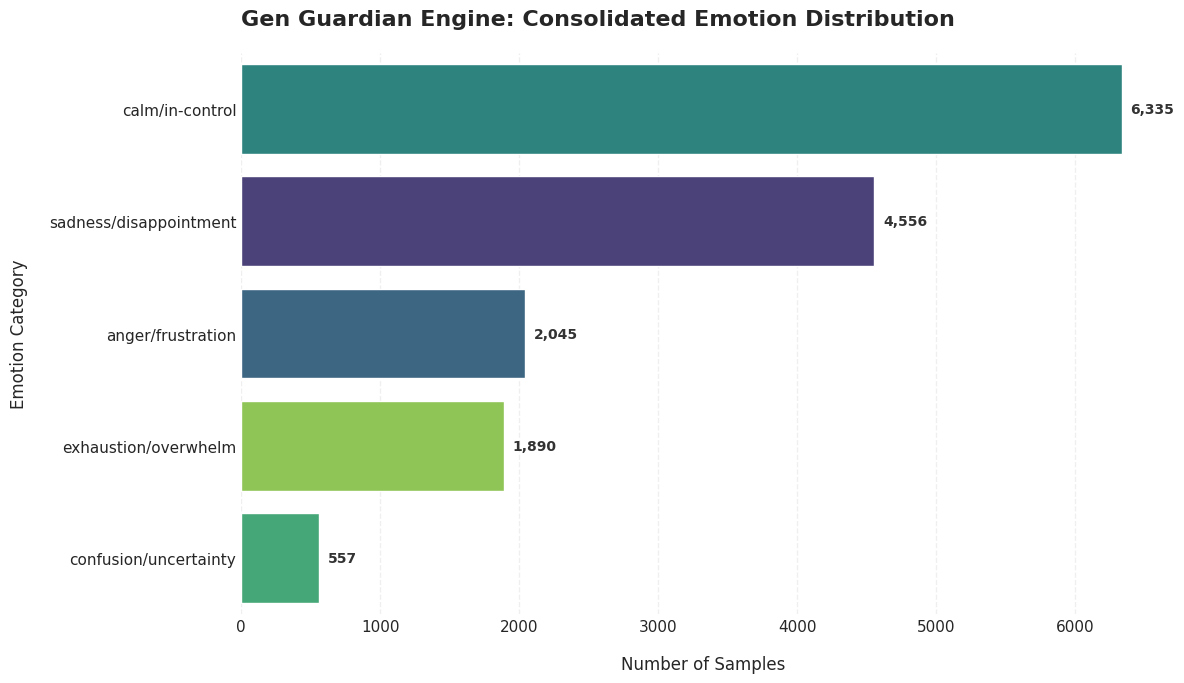

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

with sns.axes_style("white"):
    plt.figure(figsize=(12, 7))

    category_order = df['consolidated_emotion'].value_counts().index
    
    ax = sns.countplot(
        data=df, 
        y='consolidated_emotion', 
        order=category_order,
        hue='consolidated_emotion', 
        palette='viridis',
        legend=False
    )


    plt.title('Gen Guardian Engine: Consolidated Emotion Distribution', 
              fontsize=16, pad=20, fontweight='bold', loc='left')
    plt.xlabel('Number of Samples', fontsize=12, labelpad=15)
    plt.ylabel('Emotion Category', fontsize=12, labelpad=15)

    # Dynamic Label Placement
    max_width = df['consolidated_emotion'].value_counts().max()
    offset = max_width * 0.01  
    
    for p in ax.patches:
        width = p.get_width()
        ax.text(
            width + offset, 
            p.get_y() + p.get_height() / 2, 
            f'{int(width):,}', 
            ha='left', 
            va='center',
            fontsize=10,
            fontweight='600',
            color='#333333'
        )

    sns.despine(left=True, bottom=True)
    ax.xaxis.grid(True, linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [29]:
print(df.columns)

Index(['text', 'label', 'emotion_name', 'consolidated_emotion'], dtype='str')


In [30]:
from sklearn.model_selection import train_test_split


X = df['text']
y = df['consolidated_emotion']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")


def keyword_baseline_predict(text):
    text_lower = text.lower()
    scores = {
        'anger/frustration': len(re.findall(r'angry|mad|furious|hate|annoyed|stupid|idiot', text_lower)),
        'exhaustion/overwhelm': len(re.findall(r'tired|exhausted|overwhelmed|scared|fear|panic|stress', text_lower)),
        'calm/in-control': len(re.findall(r'good|happy|love|great|wonderful|peaceful|calm|relaxed', text_lower)),
        'sadness/disappointment': len(re.findall(r'sad|cry|tears|disappointed|hopeless|lonely|miss', text_lower)),
        'confusion/uncertainty': len(re.findall(r'confused|dont know|uncertain|surprised|wonder|maybe|why', text_lower)),
    }
    
    max_score = max(scores.values())
    if max_score == 0:
        return 'calm/in-control' 
    

    return [k for k, v in scores.items() if v == max_score][0]


baseline_preds = [keyword_baseline_predict(t) for t in X_test]
baseline_acc = accuracy_score(y_test, baseline_preds)
baseline_f1 = f1_score(y_test, baseline_preds, average='weighted')

print(f"\n Baseline Results:")
print(f"Accuracy: {baseline_acc:.4f}")
print(f"Weighted F1-Score: {baseline_f1:.4f}")

Training set size: 12306
Test set size: 3077

 Baseline Results:
Accuracy: 0.4374
Weighted F1-Score: 0.3427


In [31]:
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline


print("Training Linear SVM...")
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')),
    ('svm', LinearSVC(random_state=42, max_iter=5000))
])
svm_pipeline.fit(X_train, y_train)
svm_preds = svm_pipeline.predict(X_test)


print("Training Random Forest...")
rf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
rf_pipeline.fit(X_train, y_train)
rf_preds = rf_pipeline.predict(X_test)


print("MODEL COMPARISON RESULTS")


models = {
    "Baseline (Keywords)": (baseline_preds, baseline_acc, baseline_f1),
    "Linear SVM": (svm_preds, accuracy_score(y_test, svm_preds), f1_score(y_test, svm_preds, average='weighted')),
    "Random Forest": (rf_preds, accuracy_score(y_test, rf_preds), f1_score(y_test, rf_preds, average='weighted'))
}

results_df = pd.DataFrame([
    {"Model": name, "Accuracy": acc, "Weighted F1": f1}
    for name, (_, acc, f1) in models.items()
])

print(results_df.to_string(index=False))

Training Linear SVM...
Training Random Forest...


MODEL COMPARISON RESULTS
              Model  Accuracy  Weighted F1
Baseline (Keywords)  0.437439     0.342740
         Linear SVM  0.924602     0.923816
      Random Forest  0.910952     0.910779



🔍 Detailed Classification Report (SVM):
                        precision    recall  f1-score   support

     anger/frustration       0.90      0.88      0.89       409
       calm/in-control       0.95      0.98      0.96      1267
 confusion/uncertainty       0.83      0.74      0.78       112
  exhaustion/overwhelm       0.88      0.84      0.86       378
sadness/disappointment       0.94      0.93      0.93       911

              accuracy                           0.92      3077
             macro avg       0.90      0.87      0.88      3077
          weighted avg       0.92      0.92      0.92      3077



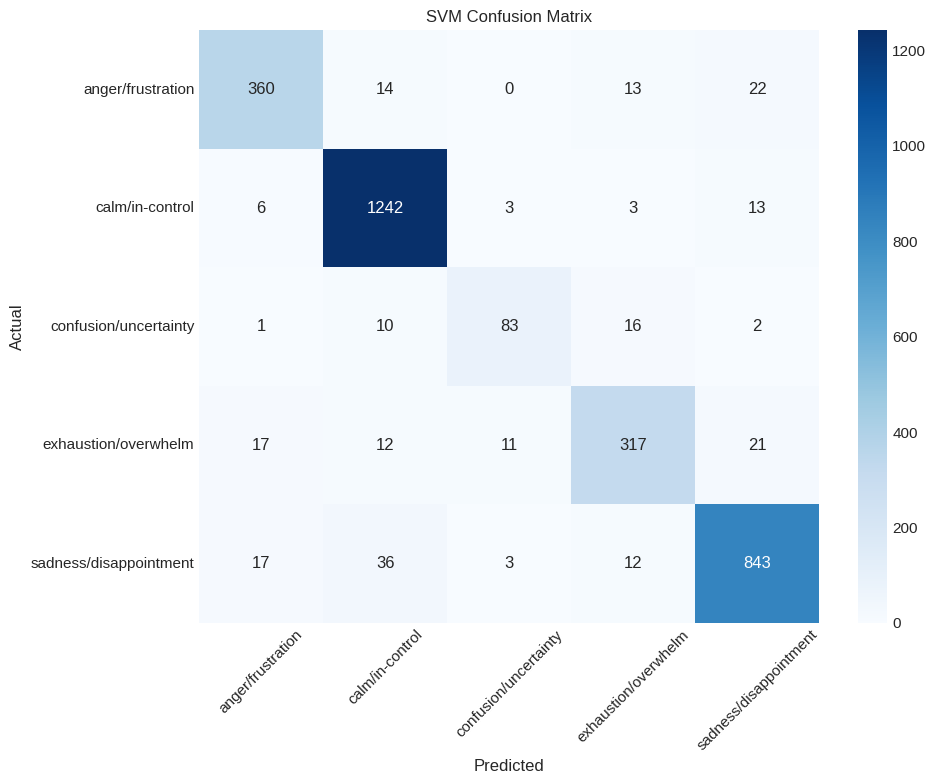


 Found 232 misclassified samples.

Sample Errors (Actual vs Predicted):
Index: 6066
Actual: anger/frustration | Predicted: sadness/disappointment
Text: 'i feel like todd is getting too stressed or tired with caleb i will take him because i dont want caleb to feel that frustration'

Index: 8172
Actual: exhaustion/overwhelm | Predicted: sadness/disappointment
Text: 'i as many others are feeling helpless that we as a world can not hold the grieving parents hands especially the mothers and grandmothers of nigeria as they desperately wait for assistance to have their girls return back home safely and let their laughter ring out through their home once again'

Index: 6207
Actual: sadness/disappointment | Predicted: anger/frustration
Text: 'im not sure why i even bothered to open this website let alone this feature but as expected its left me feeling boring poor and'

Index: 9121
Actual: exhaustion/overwhelm | Predicted: anger/frustration
Text: 'staying alone in the biology building after th

In [32]:

print("\n🔍 Detailed Classification Report (SVM):")
print(classification_report(y_test, svm_preds))


plt.figure(figsize=(10, 8))



categories = sorted(df['consolidated_emotion'].unique())
cm_svm = confusion_matrix(y_test, svm_preds, labels=categories)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=categories,
            yticklabels=categories)
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


error_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': svm_preds,
    'Text': X_test 
})


errors = error_df[error_df['Actual'] != error_df['Predicted']]

print(f"\n Found {len(errors)} misclassified samples.")
print("\nSample Errors (Actual vs Predicted):")


for idx, row in errors.head(5).iterrows():
    # Use .loc with the actual index 'idx'
    print(f"Index: {idx}")
    print(f"Actual: {row['Actual']} | Predicted: {row['Predicted']}")
    print(f"Text: '{row['Text']}'\n")

In [33]:
from sklearn.model_selection import GridSearchCV


rf_tuning_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')),
    ('rf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid_rf = {
    'rf__n_estimators': [50, 100, 200],
    'rf__max_depth': [None, 20],
}

print("Running Grid Search for Random Forest...")
grid_rf = GridSearchCV(rf_tuning_pipeline, param_grid_rf, cv=5, scoring='accuracy')
grid_rf.fit(X_train, y_train)


best_rf_model = grid_rf.best_estimator_
rf_tuned_preds = best_rf_model.predict(X_test)


results_df.loc[results_df['Model'] == 'Random Forest', 'Accuracy'] = accuracy_score(y_test, rf_tuned_preds)
results_df.loc[results_df['Model'] == 'Random Forest', 'Weighted F1'] = f1_score(y_test, rf_tuned_preds, average='weighted')

print(f" Best RF Parameters: {grid_rf.best_params_}")

Running Grid Search for Random Forest...
 Best RF Parameters: {'rf__max_depth': None, 'rf__n_estimators': 200}


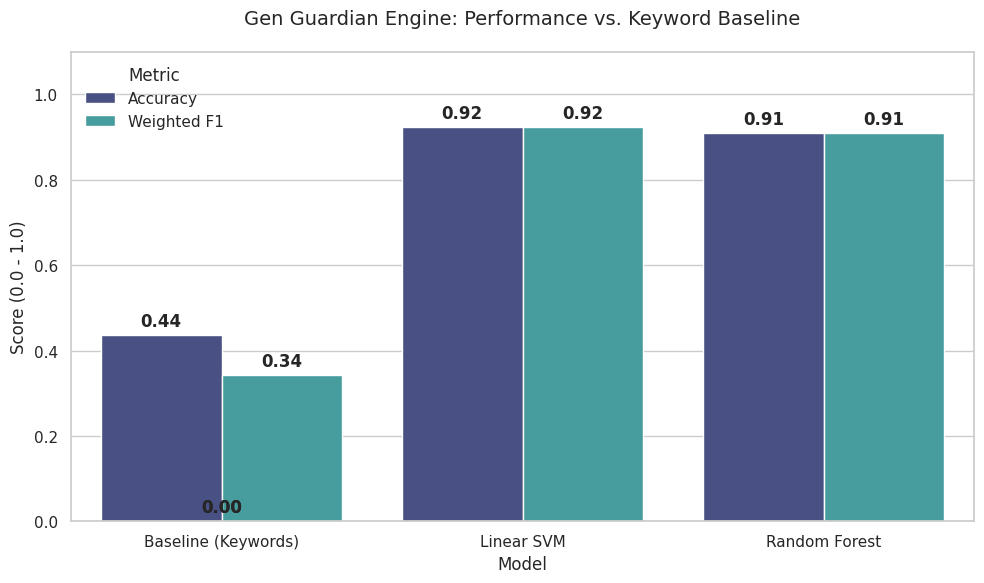

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))


df_plot = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

ax = sns.barplot(data=df_plot, x='Model', y='Score', hue='Metric', palette='mako')

plt.title('Gen Guardian Engine: Performance vs. Keyword Baseline', fontsize=14, pad=20)
plt.ylabel('Score (0.0 - 1.0)', fontsize=12)
plt.ylim(0, 1.1) 
plt.legend(title='Metric', loc='upper left')


for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 10), 
                textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()